# EDA 02 · Correlación entre categorías y subcategorías

¿Quien compra en una (sub)categoría tiende a comprar también en otra?

- **Unidad:** usuario. Por cada usuario y (sub)categoría, 1 si ha comprado algo allí en los 60 días de `shop.history_events` y 0 si no.
- **Correlación:** Pearson entre esas columnas binarias (coeficiente phi). **> 0**: se compran juntas en el mismo usuario; **< 0**: el que compra una tiende a no comprar la otra; **≈ 0**: independientes.
- **11 matrices:** 1 de las 10 categorías y 1 por categoría con sus subcategorías.

Nota: un usuario activo compra en más sitios, y esto sube un poco todas las correlaciones. Por eso conviene fijarse en las diferencias entre celdas más que en el nivel absoluto.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

for p in [Path(".env"), Path("../.env"), Path("../datathon-fme-2026/.env")]:
    if p.exists():
        for line in p.read_text().splitlines():
            k, _, v = line.partition("=")
            if k.strip():
                os.environ.setdefault(k.strip(), v.strip())
        break
API = os.environ.get("RAWTREE_API_URL", "https://api.rawtree.com")
http = requests.Session()
http.headers["Authorization"] = f"Bearer {os.environ['RAWTREE_API_KEY']}"

def sql(q):
    r = http.post(f"{API}/v1/query", json={"sql": q}, timeout=900)
    r.raise_for_status()
    return pd.DataFrame(r.json()["data"])

INK, MUTED, GRID = "#1f2328", "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED})
FIG = Path("fig"); FIG.mkdir(exist_ok=True)

## Datos: compras por usuario y subcategoría

In [2]:
d = sql("""
SELECT e.u AS u, c.cat AS category, c.sub AS subcategory, count() AS compras
FROM (SELECT user_id::String AS u, product_id::String AS p FROM shop.history_events
      WHERE event_type::String = 'purchase') AS e
INNER JOIN (SELECT product_id::String AS p, category::String AS cat, subcategory::String AS sub
            FROM shop.catalog) AS c ON c.p = e.p
GROUP BY u, category, subcategory""")
print(f"{d.u.nunique():,} usuarios con compras · {len(d):,} pares usuario-subcategoría".replace(",", "."))
sub_bin = (d.pivot_table(index="u", columns="subcategory", values="compras", aggfunc="sum", fill_value=0) > 0).astype(int)
cat_bin = (d.pivot_table(index="u", columns="category", values="compras", aggfunc="sum", fill_value=0) > 0).astype(int)
sub2cat = d.drop_duplicates("subcategory").set_index("subcategory").category
print("usuarios que compran en cada categoría (%):")
print((100 * cat_bin.mean()).round(1).sort_values(ascending=False).to_string())

51.799 usuarios con compras · 280.322 pares usuario-subcategoría


usuarios que compran en cada categoría (%):
category
Books & Media         41.4
Toys & Baby           36.8
Electronics           34.6
Computers & Gaming    33.0
Fashion               27.3
Home & Kitchen        25.9
Pets                  22.9
Sports & Outdoors     21.9
Home & Garden         20.0
Beauty & Health       19.8


In [3]:
def corr_heatmap(M, title, fname, ax=None, annotate=True):
    """Matriz de correlación con paleta divergente centrada en 0 (gris neutro = sin relación)."""
    C = M.corr()
    lim = max(0.05, float(np.nanmax(np.abs(C.values - np.eye(len(C))))))
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(0.62 * len(C) + 2.6, 0.55 * len(C) + 1.6))
    im = ax.imshow(C.values, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(C)), C.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(C)), C.index)
    if annotate:
        for i in range(len(C)):
            for j in range(len(C)):
                v = C.values[i, j]
                ax.text(j, i, "1" if i == j else f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                        color="white" if (abs(v) > 0.6 * lim or i == j) else INK)
    ax.set_title(title, loc="left", fontsize=10)
    for s in ax.spines.values():
        s.set_visible(False)
    if own:
        plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="correlación (phi)")
        plt.tight_layout()
        plt.savefig(FIG / fname, bbox_inches="tight")
        plt.show()
    return C

## 1. Categorías (10 × 10)

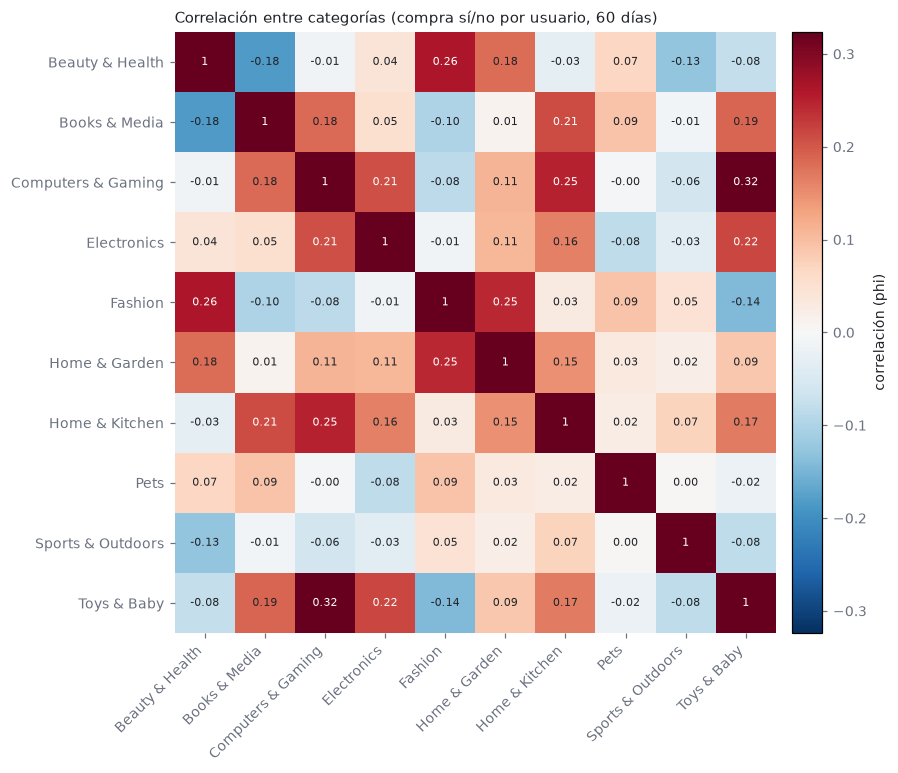

In [4]:
C_cat = corr_heatmap(cat_bin, "Correlación entre categorías (compra sí/no por usuario, 60 días)", "corr_categorias.png")

## 2. Subcategorías dentro de cada categoría

Una matriz por categoría. La escala de colores se ajusta a cada matriz para que se vean las diferencias internas: compara colores dentro de una misma matriz, no entre matrices.

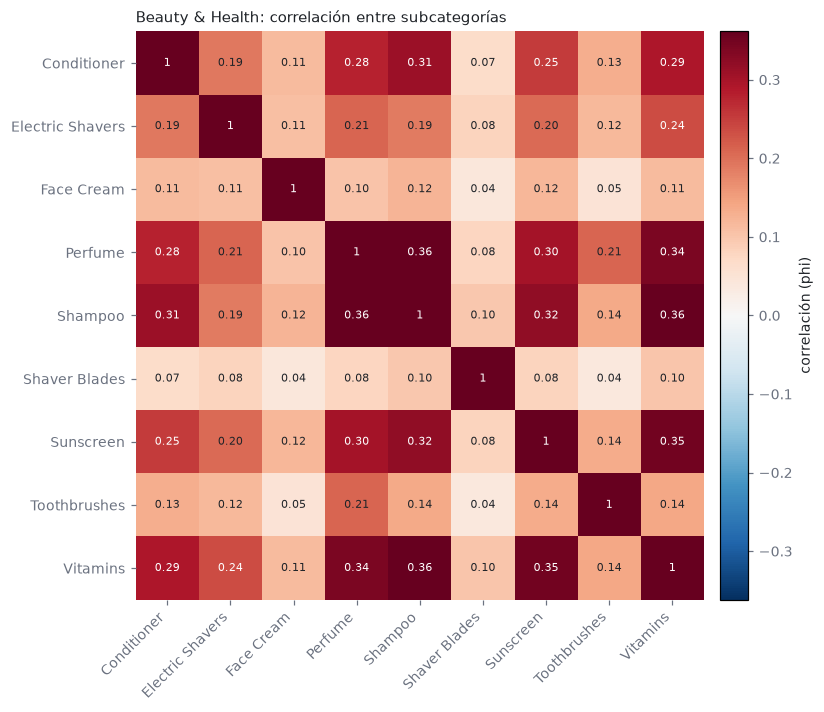

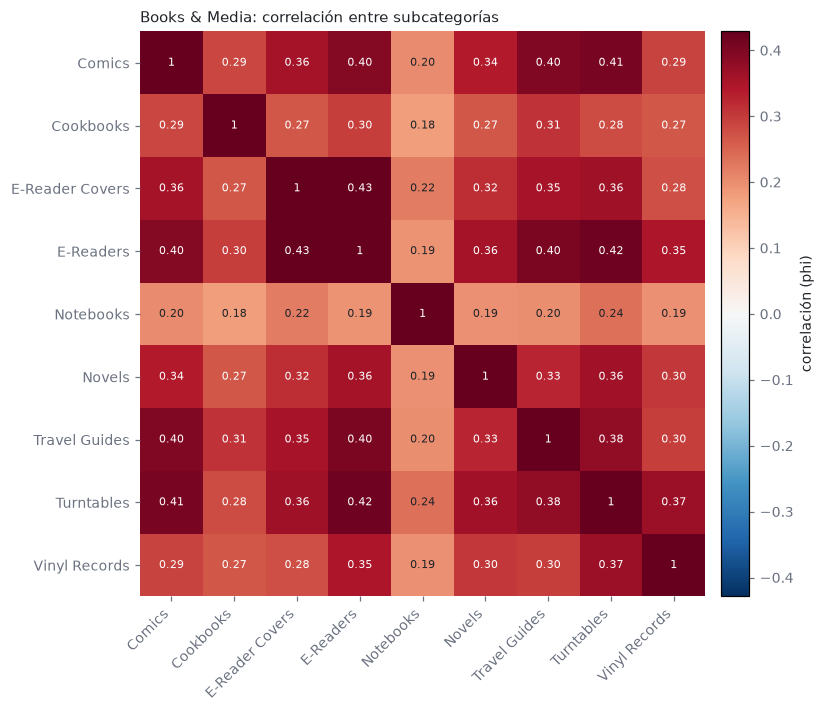

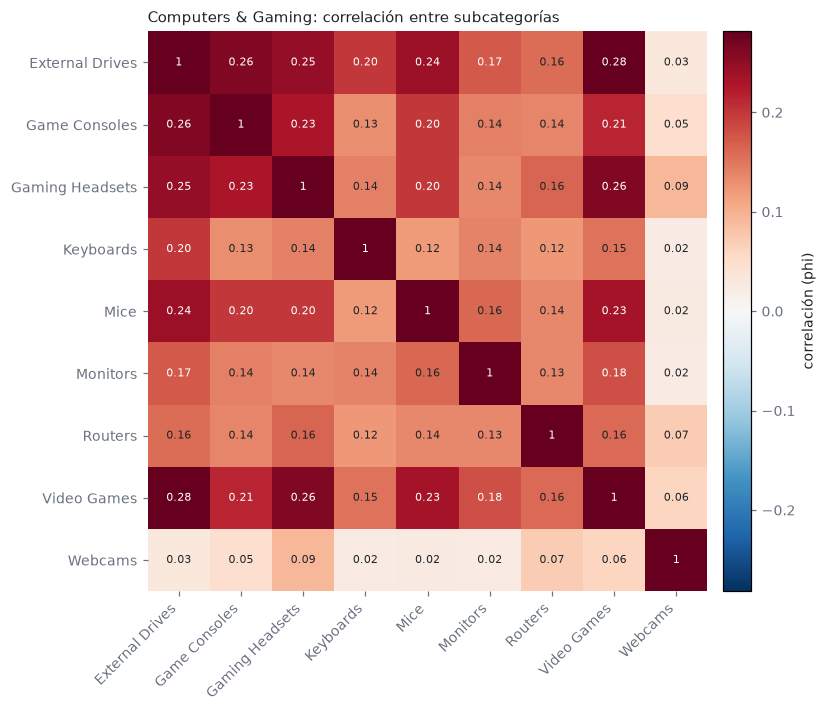

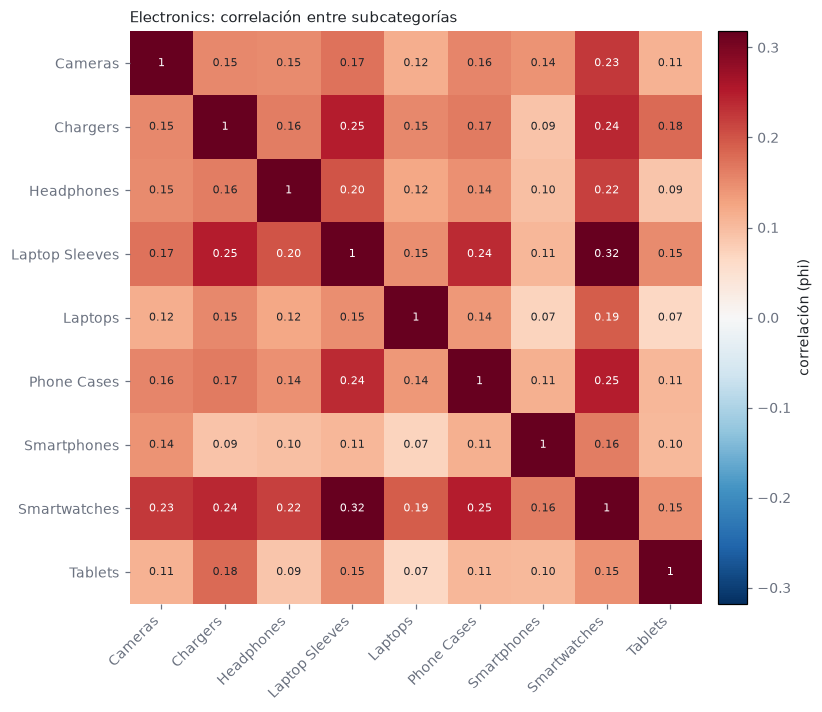

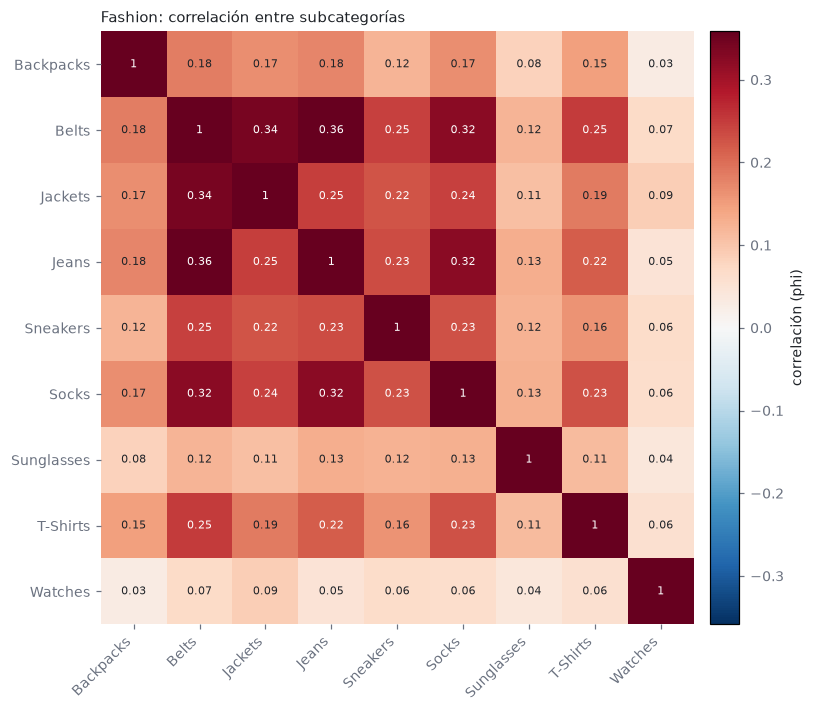

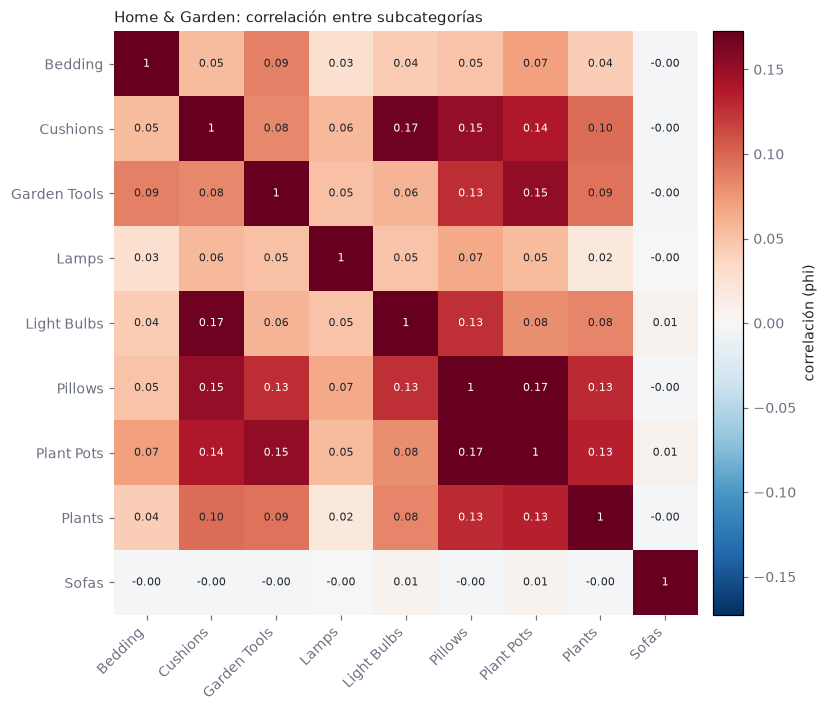

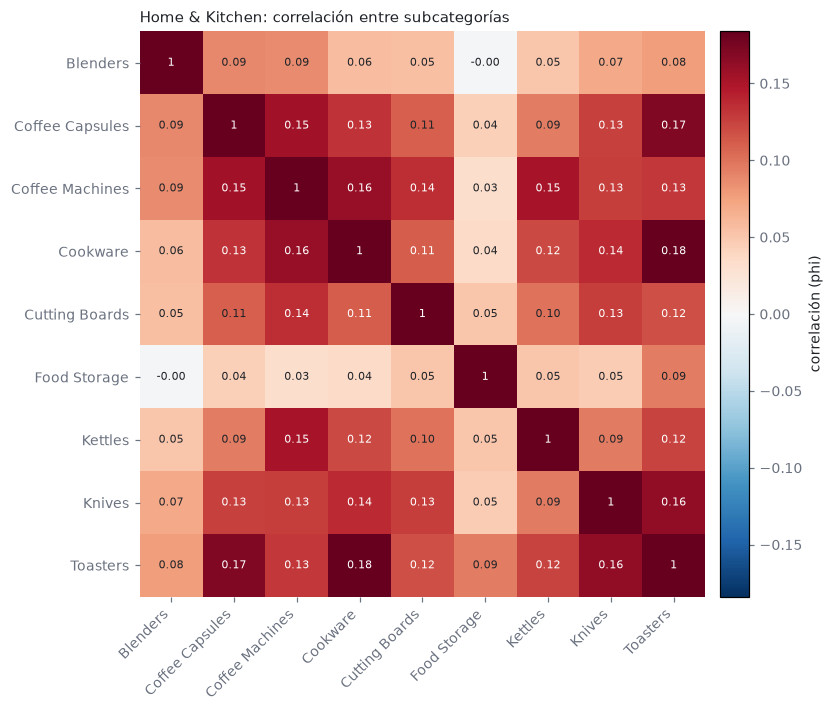

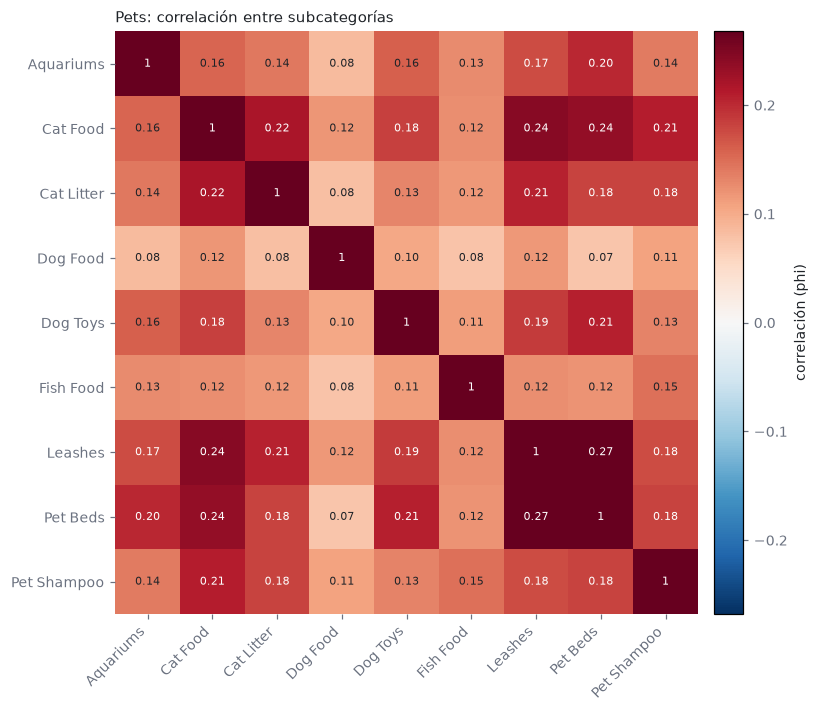

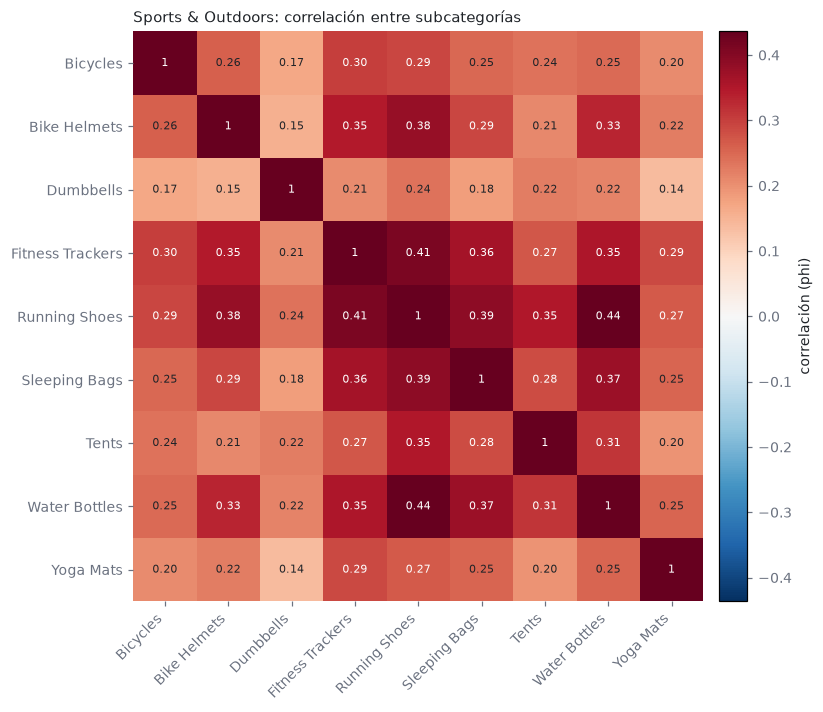

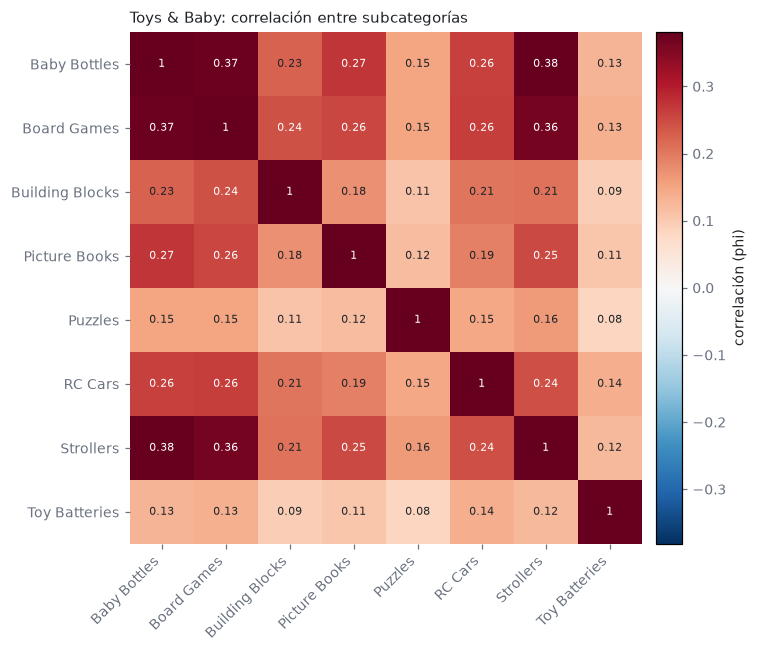

In [5]:
C_sub = {}
for cat in C_cat.index:
    subs = sorted(sub2cat[sub2cat == cat].index)
    C_sub[cat] = corr_heatmap(sub_bin[subs], f"{cat}: correlación entre subcategorías",
                              "corr_sub_" + cat.replace(" & ", "_").replace(" ", "_").lower() + ".png")

## 3. Resumen: ¿misma familia o familia distinta?

In [6]:
C_all = sub_bin.corr()
iu = np.triu_indices(len(C_all), 1)
pairs = pd.DataFrame({"a": C_all.index[iu[0]], "b": C_all.columns[iu[1]], "r": C_all.values[iu]})
pairs["misma_familia"] = pairs.a.map(sub2cat) == pairs.b.map(sub2cat)
print(pairs.groupby("misma_familia").r.describe().round(3).to_string())
print("\nPares más correlacionados:")
print(pairs.sort_values("r", ascending=False).head(10).round(3).to_string(index=False))
print("\nPares más anticorrelacionados:")
print(pairs.sort_values("r").head(5).round(3).to_string(index=False))

                count   mean    std    min    25%    50%    75%    max
misma_familia                                                         
False          3564.0  0.024  0.050 -0.110 -0.008  0.012  0.051  0.229
True            352.0  0.175  0.099 -0.003  0.107  0.155  0.242  0.436

Pares más correlacionados:
               a             b     r  misma_familia
   Running Shoes Water Bottles 0.436           True
 E-Reader Covers     E-Readers 0.429           True
       E-Readers    Turntables 0.416           True
Fitness Trackers Running Shoes 0.409           True
          Comics    Turntables 0.407           True
       E-Readers Travel Guides 0.402           True
          Comics Travel Guides 0.397           True
          Comics     E-Readers 0.395           True
   Running Shoes Sleeping Bags 0.391           True
    Baby Bottles     Strollers 0.381           True

Pares más anticorrelacionados:
           a               b      r  misma_familia
Baby Bottles           Belts -0.1